In [1]:
from all_search_algo import RankBiserial, mask_of, describe, Coverage, PermutationPValue, Lift

In [2]:
import pandas as pd
import numpy as np

df = pd.read_csv(r'final_sales_dataset.csv')

# Descriptors:city, family, promo_mean (avg promotion intensity of series, low medium high), promo_slope (trend in promotion intensity, low medium high)
# Target: sales (one trajectory per series)

In [3]:
df.head(5)

,id,date,store_nbr,family,sales,onpromotion,city,oil_price,holiday
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0,Quito,93.14,True
1,2,2013-01-01,1,BEAUTY,0.0,0,Quito,93.14,True
2,3,2013-01-01,1,BEVERAGES,0.0,0,Quito,93.14,True
3,4,2013-01-01,1,BOOKS,0.0,0,Quito,93.14,True
4,5,2013-01-01,1,BREAD/BAKERY,0.0,0,Quito,93.14,True


# Build Data

In [4]:
import time, itertools
import numpy as np
import pandas as pd
from scipy.spatial.distance import cdist

D_MAX, K, W, MIN_COV, Q, W_WIDE, U = 3, 10, 20, 0.01, 5, 200, 150

def tertiles(x):
    return pd.qcut(x.rank(method='first'), 3, labels=['low', 'medium', 'high'])
 
 
def build_data(path=r'final_sales_dataset.csv', lead_zero_frac=0.1):
    """
    - Y:     target, one row per store x family series = weekly sales, z-scored within the series
    - A:     binary descriptor matrix (rows = series, cols = "attribute == value")
    - names: labels of A's columns, same order
    - meta:  readable table per series: store_nbr (identifier only) + descriptor values
    """
    df = pd.read_csv(path, parse_dates=['date'])
    g = df.set_index('date').groupby(['store_nbr', 'family'])
 
    weekly = g['sales'].resample('W').sum().unstack('date').fillna(0)
    mu, sd = weekly.mean(1), weekly.std(1)
 
    first_sale = (weekly > 0).to_numpy().argmax(1)
    keep = ((sd > 0).to_numpy()
            & (first_sale < lead_zero_frac * weekly.shape[1]))
    Y = weekly[keep].sub(mu[keep], axis=0).div(sd[keep], axis=0)

    promo = (g['onpromotion'].resample('W').mean().unstack('date')
               .reindex(index=Y.index, columns=weekly.columns).fillna(0))
    t = np.arange(promo.shape[1], dtype=float)
    t -= t.mean()
    promo_mean = promo.mean(1)
    promo_slope = promo.sub(promo_mean, axis=0).mul(t, axis=1).sum(1) / (t ** 2).sum()
 
    # descriptor table 
    meta = (df.groupby(['store_nbr', 'family']).agg(city=('city', 'first')).loc[Y.index].reset_index())
    meta['promo_mean'] = tertiles(promo_mean.reset_index(drop=True))
    meta['promo_slope'] = tertiles(promo_slope.reset_index(drop=True))

    descriptors = ['city', 'family', 'promo_mean', 'promo_slope']
    onehot = pd.get_dummies(meta[descriptors].astype(str), prefix_sep='=')
    A = onehot.to_numpy(dtype=np.int8)
    Y = pd.DataFrame(
        Y,
        index=pd.MultiIndex.from_frame(meta[['store_nbr', 'family']]),
    )
 
    return Y, A, list(onehot.columns), meta


# Quality measure

In [5]:
# class RankBiserial:
#     """
#     Compares between-distance and within-distance with within meaning both series are in subgroup s,
#     and between meaning one series is in s and the other is not. The rank-biserial correlation
#     is the difference between the probability that a between-distance is greater than a within-distance
#     r = P(between > within) - P(between < within), which is equivalent to r = 2 * U / (nm) - 1, where
#     U is the number of combinations where between distance > within distance.
#     """

#     def __init__(self, Y):
#             self.D = cdist(Y, Y)
#             self.rowsum = self.D.sum(1)
#             self.cache = {}
    
#     def __call__(self, m):
#         key = m.tobytes()
#         if key not in self.cache:
#             n = m.sum()
#             if n < max(2, MIN_COV * len(m)) or n == len(m):
#                 self.cache[key] = None
#             else:
#                 s = self.D @ m
#                 within = s[m].sum()
#                 beta = within / (n * (n - 1))
#                 alpha = (self.rowsum[m].sum() - within) / (n * (len(m) - n))
#                 self.cache[key] = alpha / (beta + 1)
#         return self.cache[key]
    
# def mask_of(A, desc):
#         mask = np.ones(len(A), dtype=bool)
    
#         for column_index, value in desc:
#             mask &= (A[:, column_index] == value)
    
#         return mask

# # Define BUSPaS, which generates subgroup candidates from pairs of
# # similar sales trajectories and their shared descriptor values.
# def describe(desc, names):
#     return ' AND '.join(names[j] if v == 1 else f'NOT {names[j]}' for j, v in desc)

In [5]:
Y, A, names, meta = build_data()
print(f'{Y.shape[0]} series x {Y.shape[1]} weeks, {A.shape[1]} binary descriptors')

993 series x 242 weeks, 48 binary descriptors


# Beam search

In [6]:
def beam_search(A, qual, K=K, w=W, D=D_MAX, positive_only=True):
    # D = max depth
    # w = beam width
    # A = binary matrix of descriptors (rows = series, cols = attribute==value)
    # qual = quality measure (callable)
    # K = best K descriptors to return
    
    k = A.shape[1]
    values = (1,) if positive_only else (0, 1)

    # 'conds' has that (j, v) is a condition with column j of A and value v
    conds = [(j, v) for j in range(k) for v in values]
    
    # 'seeds' starts from empty descriptor, then grows by adding one condition at a time
    results, seeds, seen = {}, [()], set()
    for _ in range(D):
        beam = []
        for seed in seeds:
            used = {j for j, _ in seed}
            for c in conds:
                if c[0] in used:
                    continue
                # add condition c to the current seed descriptor, sort to canonical order
                desc = tuple(sorted(seed + (c,)))
                if desc in seen:
                    continue
                seen.add(desc)
                m = mask_of(A, desc)
                phi = qual(m)
                if phi is not None:
                    results[desc] = (phi, m)
                    beam.append((phi, desc))
        # keep top w descriptors w/ highest quality
        beam.sort(reverse=True)
        seeds = [d for _, d in beam[:w]]
    best = {}
    for desc, (phi, m) in results.items():
        key = m.tobytes()
        if key not in best or len(desc) < len(best[key][0]):
            best[key] = (desc, phi, m)
    # return top K descriptors w/ highest quality across all levels
    top = sorted(best.values(), key=lambda x: -x[1])[:K]
    return top, len(seen)

# Bottom-up Search

In [7]:
def bottom_up_search(A, qual):   
    # The distance measure in the quality measure given
    D = qual.D

    iu = np.triu_indices(len(D), 1)
    flat = D[iu]
    best = np.argpartition(flat, U)[:U]
    pairs = zip(iu[0][best], iu[1][best])
    cands = set()

    results = {}
    seeds = [()]
    seen = set()

    for i, j in pairs:
        shared = [(a, A[i, a]) for a in range(A.shape[1]) if A[i, a] == A[j, a]]

        for d in range(1, D_MAX + 1):
            #if desc in seen:
            #    continue
            #seen.add(desc)
            cands.update(itertools.combinations(shared, d))
            # m = mask_of(A, desc)
            # phi = qual(m)
            # if phi is not None:
            #     results[desc] = (phi, m)

    # Now we make a list of all our subgroups
    results = {}
    for desc in cands:
        m = mask_of(A, desc)
        key = m.tobytes()
        phi = qual(m)
        if phi is not None:
            results[key] = (desc, phi, m)
    top = sorted(results.values(), key=lambda x: -x[1])[:K]
    return top, len(cands)

# Running

In [8]:
# BS
print("Beam Search")
t0 = time.time()
top_beam, n_eval_beam = beam_search(A, RankBiserial(Y, MIN_COV=0.01))
print(f'{n_eval_beam} candidates evaluated in {time.time() - t0:.0f}s\n')

for desc, phi, m in top_beam:
    print(f'quality score = {phi:.3f}  n = {m.sum():4d}  {describe(desc, names)}')

Beam Search
1663 candidates evaluated in 0s

quality score = 5.882  n =   13  city=Quito AND family=PRODUCE
quality score = 4.153  n =   24  family=PRODUCE
quality score = 2.799  n =   17  city=Quito AND family=BEVERAGES
quality score = 2.775  n =   17  city=Quito AND family=FROZEN FOODS
quality score = 2.446  n =   10  family=LAWN AND GARDEN AND promo_mean=medium AND promo_slope=medium
quality score = 2.384  n =   11  family=LAWN AND GARDEN AND promo_mean=medium
quality score = 2.351  n =   12  family=LAWN AND GARDEN AND promo_slope=medium
quality score = 2.209  n =   17  city=Quito AND family=DAIRY
quality score = 2.181  n =   47  family=FROZEN FOODS
quality score = 2.160  n =   13  city=Quito AND family=POULTRY AND promo_mean=high


In [9]:
# BUS
print("Bottom-up Search")
t0 = time.time()
top_bus, n_eval_bus = bottom_up_search(A, RankBiserial(Y, MIN_COV=0.01))
print(f'{n_eval_bus} candidates evaluated in {time.time() - t0:.0f}s\n')

for desc, phi, m in top_bus:
    print(f"quality score = {phi:.3f}  n = {m.sum():4d}  {describe(desc, names)}")

Bottom-up Search
28168 candidates evaluated in 3s

quality score = 5.882  n =   13  city=Quito AND NOT family=GROCERY II AND family=PRODUCE
quality score = 5.216  n =   20  NOT city=Guayaquil AND NOT city=Salinas AND family=PRODUCE
quality score = 4.933  n =   22  NOT city=Salinas AND NOT city=Santo Domingo AND family=PRODUCE
quality score = 4.929  n =   22  NOT city=Machala AND NOT city=Salinas AND family=PRODUCE
quality score = 4.898  n =   22  NOT city=Daule AND NOT city=Salinas AND family=PRODUCE
quality score = 4.877  n =   22  NOT city=Loja AND NOT city=Salinas AND family=PRODUCE
quality score = 4.854  n =   23  NOT city=Salinas AND NOT family=LAWN AND GARDEN AND family=PRODUCE
quality score = 4.849  n =   22  NOT city=Cuenca AND NOT city=Salinas AND family=PRODUCE
quality score = 4.749  n =   21  NOT city=Ambato AND NOT city=Salinas AND family=PRODUCE
quality score = 4.333  n =   20  NOT city=Guayaquil AND NOT city=Santo Domingo AND family=PRODUCE


In [10]:
for i, (desc_i, phi_i, m_i) in enumerate(top_beam, 1):
    print(f"\nCandidate {i}: r = {phi_i:.3f}, n = {m_i.sum()}, {describe(desc_i, names)}")
    print(meta.loc[m_i].head(5).to_string(index=False))


Candidate 1: r = 5.882, n = 13, city=Quito AND family=PRODUCE
 store_nbr  family  city promo_mean promo_slope
         1 PRODUCE Quito       high        high
         2 PRODUCE Quito       high        high
         3 PRODUCE Quito       high        high
         4 PRODUCE Quito       high        high
         6 PRODUCE Quito       high        high

Candidate 2: r = 4.153, n = 24, family=PRODUCE
 store_nbr  family          city promo_mean promo_slope
         1 PRODUCE         Quito       high        high
         2 PRODUCE         Quito       high        high
         3 PRODUCE         Quito       high        high
         4 PRODUCE         Quito       high        high
         5 PRODUCE Santo Domingo       high        high

Candidate 3: r = 2.799, n = 17, city=Quito AND family=BEVERAGES
 store_nbr    family  city promo_mean promo_slope
         1 BEVERAGES Quito       high        high
         2 BEVERAGES Quito       high        high
         3 BEVERAGES Quito       high        high


In [11]:
for i, (desc_i, phi_i, m_i) in enumerate(top_bus, 1):
    print(f"\nCandidate {i}: r = {phi_i:.3f}, n = {m_i.sum()}, {describe(desc_i, names)}")
    print(meta.loc[m_i].head(5).to_string(index=False))


Candidate 1: r = 5.882, n = 13, city=Quito AND NOT family=GROCERY II AND family=PRODUCE
 store_nbr  family  city promo_mean promo_slope
         1 PRODUCE Quito       high        high
         2 PRODUCE Quito       high        high
         3 PRODUCE Quito       high        high
         4 PRODUCE Quito       high        high
         6 PRODUCE Quito       high        high

Candidate 2: r = 5.216, n = 20, NOT city=Guayaquil AND NOT city=Salinas AND family=PRODUCE
 store_nbr  family          city promo_mean promo_slope
         1 PRODUCE         Quito       high        high
         2 PRODUCE         Quito       high        high
         3 PRODUCE         Quito       high        high
         4 PRODUCE         Quito       high        high
         5 PRODUCE Santo Domingo       high        high

Candidate 3: r = 4.933, n = 22, NOT city=Salinas AND NOT city=Santo Domingo AND family=PRODUCE
 store_nbr  family  city promo_mean promo_slope
         1 PRODUCE Quito       high        high
   

In [ ]:
coverage = Coverage(MIN_COV)
D = cdist(Y, Y)
lift = Lift(D, MIN_COV)
quality = RankBiserial(Y, MIN_COV)
pval = PermutationPValue(quality, R=999)

rows = []
for i, (desc_i, phi_i, m_i) in enumerate(top_beam, 1):
    rows.append({
        'subgroup': f'S{i}',
        'description': describe(desc_i, names),
        'n': int(m_i.sum()),
        'quality': phi_i,
        'coverage': coverage(m_i),
        'lift': lift(m_i),
        'p_value': pval(m_i),
    })

results = pd.DataFrame(rows)
print(results.to_string(index=False))

subgroup                                                         description  n  quality  coverage     lift  p_value
      S1                                       city=Quito AND family=PRODUCE 13 5.881991  0.013092 9.548305    0.001
      S2                                                      family=PRODUCE 24 4.153335  0.024169 5.812209    0.001
      S3                                     city=Quito AND family=BEVERAGES 17 2.799288  0.017120 3.742864    0.001
      S4                                  city=Quito AND family=FROZEN FOODS 17 2.775311  0.017120 3.143462    0.001
      S5 family=LAWN AND GARDEN AND promo_mean=medium AND promo_slope=medium 10 2.445929  0.010070 2.875006    0.001
      S6                        family=LAWN AND GARDEN AND promo_mean=medium 11 2.384379  0.011078 2.789479    0.001
      S7                       family=LAWN AND GARDEN AND promo_slope=medium 12 2.350947  0.012085 2.731231    0.001
      S8                                         city=Quito AND 

# Plots

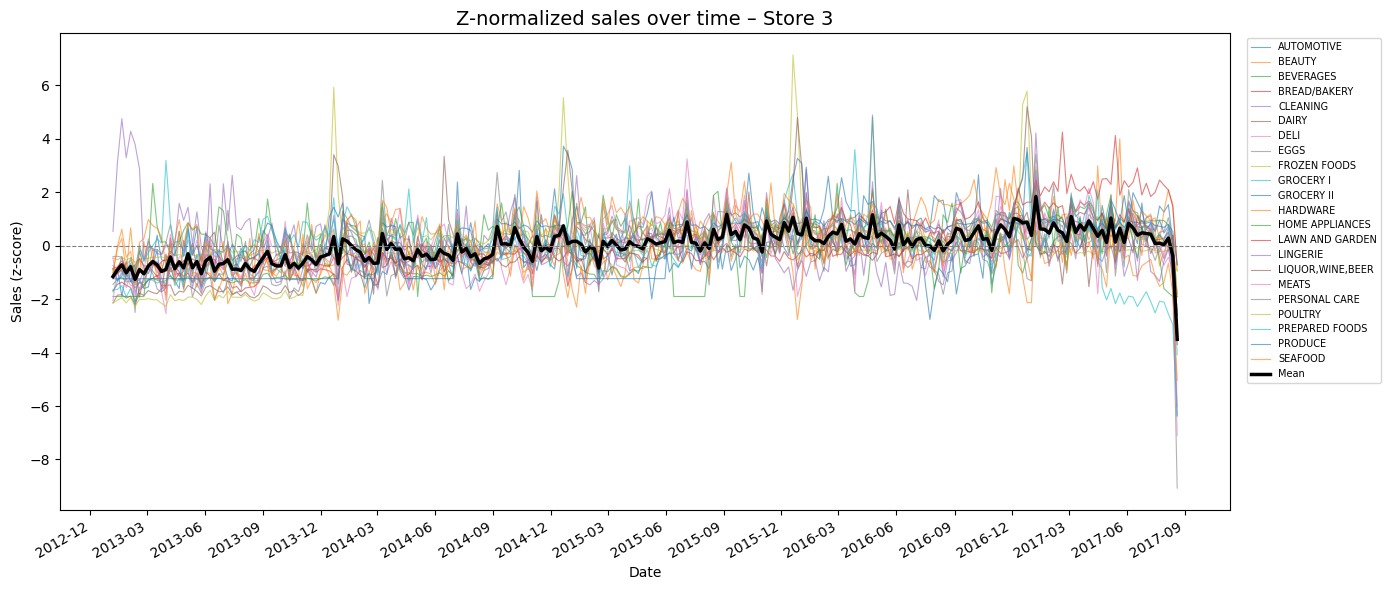

In [ ]:
# Example code to make a plot of sales trajectories using store number 3.

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

store1 = Y[Y.index.get_level_values('store_nbr') == 3]

dates = pd.to_datetime(store1.columns)

fig, ax = plt.subplots(figsize=(14, 6))

for idx, row in store1.iterrows():
    label = idx[1:] if isinstance(idx, tuple) else idx
    label = ', '.join(map(str, label)) if isinstance(label, tuple) else str(label)
    ax.plot(dates, row.values, linewidth=0.8, alpha=0.6, label=label)

# Optional: overall average trend across all series for store 3
ax.plot(dates, store1.mean(axis=0).values, color='black', linewidth=2.5, label='Mean')

ax.set_title('Z-normalized sales over time – Store 3', fontsize=14)
ax.set_xlabel('Date')
ax.set_ylabel('Sales (z-score)')
ax.axhline(0, color='grey', linestyle='--', linewidth=0.8)
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
fig.autofmt_xdate()

ax.legend(bbox_to_anchor=(1.01, 1), loc='upper left', fontsize=7, ncol=1)
plt.tight_layout()
plt.show()

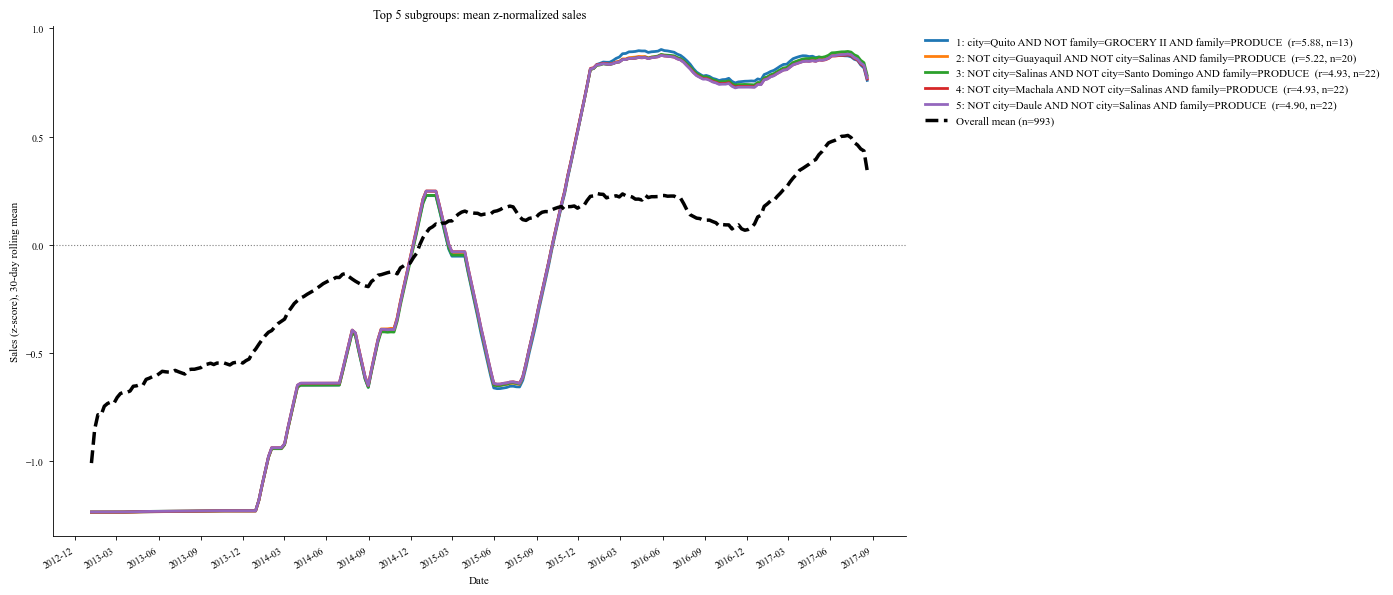

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib as mpl

# Sample code for nicer styling of plots.
mpl.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['Times New Roman', 'Times', 'DejaVu Serif'],
    'mathtext.fontset': 'stix',
    'font.size': 8,
    'axes.labelsize': 8,
    'axes.titlesize': 9,
    'legend.fontsize': 7,
    'xtick.labelsize': 7,
    'ytick.labelsize': 7,
    'axes.linewidth': 0.6,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'xtick.major.width': 0.6,
    'ytick.major.width': 0.6,
    'xtick.major.size': 3,
    'ytick.major.size': 3,
    'lines.linewidth': 1.2,
    'legend.frameon': False,
    'savefig.dpi': 300,
    'savefig.bbox': 'tight',
    'pdf.fonttype': 42,          
    'ps.fonttype': 42,
})


def mask_from_filters(meta, **filters):
    mask = pd.Series(True, index=meta.index)
    for col, val in filters.items():
        if isinstance(val, (list, tuple, set)):
            mask &= meta[col].isin(val)
        else:
            mask &= meta[col] == val
    return mask.values


def select_series(Y, meta, mask):
    keys = meta.loc[mask, list(Y.index.names)]
    return Y.loc[pd.MultiIndex.from_frame(keys)]


def plot_k_subgroups(Y, meta, beam, names, k=5, smooth=30, baseline='overall'):
    # Plot the top k subgroups.
    # smooth: number of days for rolling mean smoothing (None for no smoothing and pure ugliness)
    dates = pd.to_datetime(Y.columns)

    def prep(s):
        return s.rolling(smooth, min_periods=1).mean() if smooth else s

    fig, ax = plt.subplots(figsize=(14, 6))
    union_mask = np.zeros(len(meta), dtype=bool)

    for i, (desc_i, phi_i, m_i) in enumerate(beam[:k], 1):
        sub = select_series(Y, meta, m_i)
        union_mask |= np.asarray(m_i)
        ax.plot(dates, prep(sub.mean(axis=0)).values, linewidth=2,
                label=f'{i}: {describe(desc_i, names)}  (r={phi_i:.2f}, n={len(sub)})')

    if baseline == 'rest':
        base = Y.drop(select_series(Y, meta, union_mask).index)
        base_label = f'Rest mean (in none of the {k} subgroups, n={len(base)})'
    else:
        base = Y
        base_label = f'Overall mean (n={len(base)})'

    ax.plot(dates, prep(base.mean(axis=0)).values, color='black', linewidth=2.5,
            linestyle='--', label=base_label)

    ax.axhline(0, color='grey', linestyle=':', linewidth=0.8)
    ax.set_title(f'Top {k} subgroups: mean z-normalized sales')
    ax.set_xlabel('Date')
    ax.set_ylabel('Sales (z-score)' + (f', {smooth}-day rolling mean' if smooth else ''))
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    fig.autofmt_xdate()
    ax.legend(bbox_to_anchor=(1.01, 1), loc='upper left', fontsize=8)
    plt.tight_layout()
    plt.show()


plot_k_subgroups(Y, meta, top_bus, names, k=5, smooth=30)

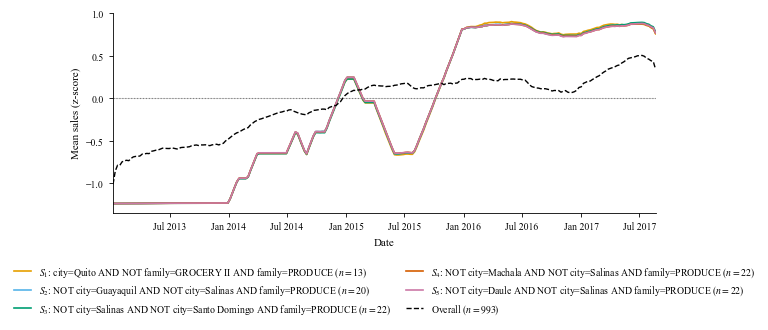

In [14]:
colors = ['#E69F00', '#56B4E9', '#009E73', '#D55E00', '#CC79A7', '#0072B2', '#F0E442']
SINGLE_COL, DOUBLE_COL = 3.5, 7.0


def plot_subgroups_nice(Y, meta, beam, names, k=5, smooth=30, baseline='overall',
                         width=DOUBLE_COL, height=2.6, savepath=None):
    dates = pd.to_datetime(Y.columns)

    def prep(s):
        return s.rolling(smooth, min_periods=1).mean() if smooth else s

    fig, ax = plt.subplots(figsize=(width, height))
    union_mask = np.zeros(len(meta), dtype=bool)

    for i, (desc_i, phi_i, m_i) in enumerate(beam[:k]):
        sub = select_series(Y, meta, m_i)
        union_mask |= np.asarray(m_i)
        ax.plot(dates, prep(sub.mean(axis=0)).values, color=colors[i % len(colors)],
                label=f'$S_{i+1}$: {describe(desc_i, names)} ($n={len(sub)}$)')

    if baseline == 'rest':
        base = Y.drop(select_series(Y, meta, union_mask).index)
        base_label = f'Complement ($n={len(base)}$)'
    else:
        base = Y
        base_label = f'Overall ($n={len(base)}$)'

    ax.plot(dates, prep(base.mean(axis=0)).values, color='black',
            linestyle='--', linewidth=1.0, label=base_label)

    ax.axhline(0, color='0.75', linewidth=0.5, zorder=0)
    ax.axhline(0, color='grey', linestyle=':', linewidth=0.8)
    ax.set_xlabel('Date')
    ax.set_ylabel('Mean sales (z-score)')
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
    ax.margins(x=0)

    ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.22), ncol=2,
              handlelength=1.8, columnspacing=1.5)

    if savepath:
        fig.savefig(savepath)
    plt.show()



plot_subgroups_nice(Y, meta, top_bus, names, k=5, smooth=30,
                     #savepath='top5_subgroups.pdf'
                     )